# 05 · AVBench, the scorecard and the metrics

How av_world scores a driving policy: the leaderboard, the av_world score (0-100) and the eight absolute checks a deployable
policy should pass, and how to tune a hand-written driver against them. ~3 minutes.

[Website](https://haggler3.github.io/av_world/) · [All notebooks](README.md) · [README](../README.md)

In [1]:
%matplotlib inline
import os, subprocess, sys
def _repo():  # this notebook inside a clone of the repository, or anywhere else (Colab): fetch it
    p = os.path.abspath("")
    while p != os.path.dirname(p):
        if os.path.exists(os.path.join(p, "xnet", "sim.py")):
            return p
        p = os.path.dirname(p)
    if not os.path.exists("av_world"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/haggler3/av_world"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "av_world"], check=True)
    return os.path.abspath("av_world")
os.chdir(_repo()); sys.path.insert(0, os.getcwd())
import time
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
import av_world
print("av_world", av_world.__version__, "in", os.getcwd())

av_world 0.4.0 in /home/user/av_world


## The leaderboard

Every entry ran on the same 11 scenarios, from the same warm states and random numbers. The score blends safety (crashes per hour,
with and without the safety envelope), comfort, progress and how much the policy leans on the envelope; see
[docs/METRICS.md](../docs/METRICS.md).

In [2]:
import json
from avrl import scorecard as SC
lb = json.load(open("results/bench/leaderboard.json"))
names = lb["scenarios"]
rank = sorted(lb["scores"], key=lambda p: -np.mean([lb["scores"][p][n]["av_score"] for n in names if n in lb["scores"][p]]))
print(f"{'policy':62s} {'score':>6s} {'checks passed':>14s}")
for p in rank:
    sc = [lb["scores"][p][n]["av_score"] for n in names if n in lb["scores"][p]]
    ab = lb.get("absolute", {}).get(p, {})
    passed = sum(sum(v.values()) for v in ab.values())
    print(f"{p:62s} {np.mean(sc):6.1f} {passed:5d}/{8 * len(ab):<3d}")

policy                                                          score  checks passed
rule-based AV                                                    77.2   104/144
PPO + barrier teacher, speed + jaywalkers (phase 3)              56.8   120/144
PPO + barrier teacher, then no filter (phase 2)                  50.3   123/144
PPO, full world, 10x envelope penalty                            49.2   104/144
PPO + barrier teacher, then no filter (phase 2, GPU retrain)     48.7   108/144
PPO + barrier teacher, speed + jaywalkers (phase 3, GPU retrain)   46.6   112/144
latent world-model planner v2 (wm-mpc)                           46.0    17/24 
PPO + barrier teacher (phase 1)                                  42.9   115/144
PPO + barrier teacher (phase 1, GPU retrain)                     35.7   107/144
PPO, 234k steps (xnet3)                                           6.1    76/144
latent world-model planner (wm-mpc)                               0.8     8/24 
PPO, 130k steps (xnet)           

## The eight absolute checks

In [3]:
for k, (desc, _) in SC.ABSOLUTE.items():
    print(f"  {k:20s} {desc}")

  safer than people    crashes per AV-hour with the envelope at most half the humans' rate in the same run (operators report 55-90 % reductions against human benchmarks)
  comfortable          at least 95 % of 20 s windows free of braking harder than -4 m/s^2 (nuPlan's comfort bound, -4.05)
  keeps up             AV mean speed at least the humans' in the same run
  light touch          the envelope cuts the policy's command in at most 2 % of AV time
  safer unaided        with no filter, crashes per AV-hour at most half the humans' rate
  lawful               no red-light runs at all, unaided
  right of way         no junction entries ahead of a car with priority, unaided
  inside the barrier   unaided, at most 0.2 % of moving time outside the control barrier function's safe set


## Where each policy fails

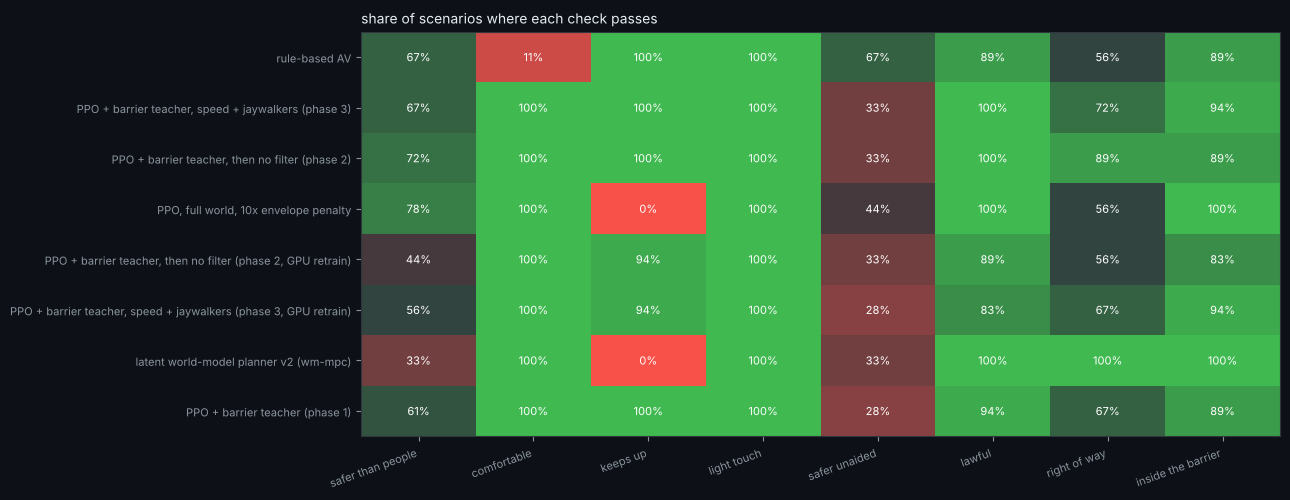

In [4]:
import matplotlib.colors as mcolors
plt.rcParams.update({"axes.titlecolor": "#e6edf3", "axes.labelcolor": "#8b949e"})
def dark(ax):
    ax.set_facecolor("#0d1117"); ax.tick_params(colors="#8b949e", labelsize=8); ax.grid(color="#21262d")
    for s in ax.spines.values(): s.set_color("#30363d")
    ax.title.set_color("#e6edf3"); ax.xaxis.label.set_color("#8b949e"); ax.yaxis.label.set_color("#8b949e")
pols = [p for p in rank if p in lb.get("absolute", {})][:8]
checks = list(SC.ABSOLUTE)
M = np.array([[np.mean([lb["absolute"][p][n][c] for n in lb["absolute"][p]]) for c in checks] for p in pols])
fig, ax = plt.subplots(figsize=(13, 0.45 * len(pols) + 1.5), facecolor="#0d1117")
ax.imshow(M, cmap=mcolors.LinearSegmentedColormap.from_list("pf", ["#f85149", "#30363d", "#3fb950"]), vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(checks)), checks, rotation=20, ha="right"); ax.set_yticks(range(len(pols)), pols)
for i in range(len(pols)):
    for j in range(len(checks)):
        ax.text(j, i, f"{M[i, j]:.0%}", ha="center", va="center", color="w", fontsize=8)
ax.set_title("share of scenarios where each check passes", loc="left", fontsize=10); dark(ax); ax.grid(False)
fig.tight_layout(); display(fig); plt.close(fig)

## Tune a hand-written driver

`examples/my_policy.py` is the Intelligent Driver Model as a policy. `bench.evaluate` takes any such function. Its time headway
`T` trades progress for safety and comfort; two settings on the nominal scenario (~1 min each):

In [5]:
from functools import partial
from avrl import bench
from examples.my_policy import careful_idm
res = {}
for T in (0.8, 1.8):
    t = time.time()
    s = bench.evaluate(partial(careful_idm, T=T), ["nominal"])["scenarios"]["nominal"]
    res[T] = s
    m = s["metrics"]
    fails = [k for k, ok in SC.absolute_checks(m).items() if not ok]
    print(f"T = {T} s: score {s['av_score']:5.1f}  crashes/AV-h unaided {m['crash_per_h_unaided']:.3f} (humans {m['human_crash_per_h']:.3f})  "
          f"comfort {m['comfort_pass']:.3f}  progress {m['progress']:.3f}  fails: {fails or 'none'}  ({time.time() - t:.0f} s)")

T = 0.8 s: score  83.8  crashes/AV-h unaided 0.000 (humans 0.007)  comfort 0.853  progress 0.985  fails: ['comfortable', 'keeps up']  (28 s)


T = 1.8 s: score  81.0  crashes/AV-h unaided 0.000 (humans 0.014)  comfort 0.852  progress 0.952  fails: ['comfortable', 'keeps up']  (28 s)


## Reading the metrics honestly

Crashes are rare, so a rate from a short run is uncertain. The scorecard reports a 95 % upper bound next to the rate
(`crash_ucb95_per_h`), from a Poisson interval: with zero crashes in `t` hours the bound is 3/t, not zero.

In [6]:
for T, s in res.items():
    m = s["metrics"]
    print(f"T = {T}: {m['av_hours']:.1f} AV-hours, crashes/h {m['crash_per_h']:.3f}, 95 % upper bound {m['crash_ucb95_per_h']:.3f}")
print("zero crashes in 40 AV-hours ->", round(SC.poisson_ucb(0, 40), 3), "per hour at most (95 %)")

T = 0.8: 41.9 AV-hours, crashes/h 0.000, 95 % upper bound 0.071
T = 1.8: 42.2 AV-hours, crashes/h 0.000, 95 % upper bound 0.071
zero crashes in 40 AV-hours -> 0.075 per hour at most (95 %)


## Next

* Submit your own: `examples/my_policy.py` prints your row against the leaderboard.
* Every metric and how it is computed: [docs/METRICS.md](../docs/METRICS.md).